In [42]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scipy.stats import linregress
import dask
from matplotlib.patches import Rectangle
import cartopy.crs as ccrs, cartopy.feature as cfeature
import seaborn as sns
from dask_jobqueue import PBSCluster
from dask.distributed import Client
from cartopy.feature import ShapelyFeature
from cartopy.io.shapereader import Reader
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42        # TrueType instead of Type 3

 
mpl.rcParams['pdf.fonttype'] = 42 

In [34]:
ds_msl_recon = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/L1/dyn_adj/MSL_1950/dyn_adj_circulation_ERA5_India_50_34_20_74.nc')
ds_msl_anom = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/AMJJAS_anom/MSL_ERA5_India_AMJJAS_anom.nc')
ds_msl_recon_uf = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment_unforced_smooth/L1/dyn_adj/dyn_adj_circulation_ERA5_India_50_34_20_74.nc')
ds_msl_anom_uf = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment_unforced_smooth/AMJJAS_anom/MSL_ERA5_India_AMJJAS_anom.nc')

In [35]:
ds_msl_recon = ds_msl_recon.sel(time=ds_msl_recon.time.dt.month.isin([5,6]))['dynamic_circulation']
ds_msl_anom = ds_msl_anom.sel(time=ds_msl_anom.time.dt.month.isin([5,6]))['anom']
ds_msl_recon_uf = ds_msl_recon_uf.sel(time=ds_msl_recon_uf.time.dt.month.isin([5,6]))['dynamic_circulation']
ds_msl_anom_uf = ds_msl_anom_uf.sel(time=ds_msl_anom_uf.time.dt.month.isin([5,6]))['anom']

In [36]:
ds_corr = xr.corr(ds_msl_recon,ds_msl_anom,dim='time')
ds_corr_uf = xr.corr(ds_msl_recon_uf,ds_msl_anom_uf,dim='time')

In [37]:
ds_corr = dask.compute(ds_corr)[0]
ds_corr_uf = dask.compute(ds_corr_uf)[0]

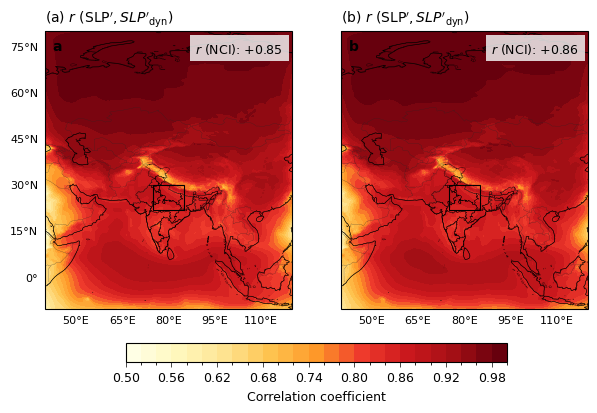

In [47]:
maps = [ds_corr, ds_corr_uf]
cols = ["T2m anomaly", "T2m dynamic adjustment"]
PC = ccrs.PlateCarree()
shp_file = '/glade/derecho/scratch/adixit/India_Heatwave/shapefiles/india_st.shp'
shape_feature = ShapelyFeature(Reader(shp_file).geometries(), ccrs.PlateCarree(),edgecolor='black', facecolor='none',lw=0.5)
box = dict(lat=slice(30, 22), lon=slice(75, 85)) 

#mpl.rcParams.update(mpl.rcParamsDefault)
def box_mean(da):
    b = da.sel(**box)
    return b.mean(dim=["lat", "lon"])

ttls = [r"(a) $r\ (\mathrm{SLP}', SLP'_{\mathrm{dyn}})$", r"(b) $r\ (\mathrm{SLP}', SLP'_{\mathrm{dyn}})$"]

fig, axs = plt.subplots(1, 2, figsize=(7, 5.5), subplot_kw={'projection': PC})

for j, (ax, da) in enumerate(zip(axs, maps)):
    im = da.plot.contourf(ax=ax, transform=PC, levels=np.arange(0.5,1.01,0.020),cmap=cmap, add_colorbar=False)
    ax.coastlines(resolution='50m', linewidth=0.2, color='black')
    ax.add_feature(shape_feature, edgecolor='k', lw=0.25)
    ax.coastlines(lw=0.4); ax.add_feature(cfeature.BORDERS, edgecolor='#252525',lw=0.15)
    ax.add_patch(Rectangle((75, 22), 10, 8, fill=False, ec="k", lw=.8, transform=PC))
    ax.set_title(ttls[j], fontsize=10, loc='left')
    gl = ax.gridlines(draw_labels=True, lw=0)
    gl.xlocator = mpl.ticker.FixedLocator(range(20, 121, 15))
    gl.ylocator = mpl.ticker.FixedLocator(range(0, 90, 15))
    gl.top_labels = gl.right_labels = False
    gl.bottom_labels, gl.left_labels = (1), (j == 0)
    gl.xlabel_style = gl.ylabel_style = {"size": 8}
    ax.text(.03, .97, "ab"[j], transform=ax.transAxes, weight='bold', va='top')
    ax.text(103, 73, f"$r$ (NCI): {box_mean(da):+.2f}".replace("-", "−"), transform=PC,
            ha='center', fontsize=9, bbox=dict(fc='#f0f0f0', ec='none', alpha=.85))

cb = fig.colorbar(im, ax=axs, orientation='horizontal', fraction=.045, pad=.08)
cb.set_label("Correlation coefficient", fontsize=9)
cb.ax.tick_params(labelsize=9, width=0.5)
fig.savefig('TargetSLP-verify.pdf', dpi=300, format='pdf', transparent=True)
plt.show()

In [46]:
import matplotlib as mpl
mpl.rcdefaults()

In [ ]:
mpl.rcParams['mathtext.fontset'] = 'dejavusans'

In [13]:
['#ffffe5','#fff7bc','#fee391','#fec44f','#fe9929','#ef3b2c','#cb181d','#a50f15','#67000d']

['#ffffe5',
 '#fff7bc',
 '#fee391',
 '#fec44f',
 '#fe9929',
 '#ef3b2c',
 '#cb181d',
 '#a50f15',
 '#67000d']

In [14]:
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('custom', ['#ffffe5','#fff7bc','#fee391','#fec44f','#fe9929','#ef3b2c','#cb181d','#a50f15','#67000d'])

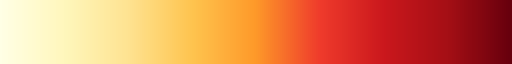

In [15]:
cmap